# EDA 2 — Users: activity, histories, cold start and history-based signals

Training split of **MIND-small**, except where validation and test are needed to count new users. Inputs are the processed files from
`1_Data_Preparation/1. data_preparation.ipynb`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Project root = the folder that contains 1_Data_Preparation/processed (written by 1. data_preparation.ipynb)
CODE_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "run_all.py").is_file()
)
ROOT = (
    Path(os.environ.get("NEWSREC_ROOT", CODE_ROOT / "runs/mindsmall-epoch"))
    .expanduser()
    .resolve()
)
PROCESSED = ROOT / "1_Data_Preparation" / "processed"
FIG_DIR = ROOT / "2_EDA" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /Users/anhminhhoang/Documents/GitHub/BT4222-Group-6-


In [2]:
# 1. Load the processed training tables
imp_cols = [
    "impression_uid",
    "user_code",
    "timestamp",
    "history_len",
    "slate_len",
    "n_clicks",
]
cand_cols = ["impression_uid", "user_code", "timestamp", "news_code", "clicked"]
imp = pd.read_parquet(PROCESSED / "impressions_train.parquet", columns=imp_cols)
cand = pd.read_parquet(PROCESSED / "candidates_train.parquet", columns=cand_cols)
news = pd.read_parquet(
    PROCESSED / "news_catalogue.parquet",
    columns=["news_code", "category", "exposures_train"],
)


# 2. Helper used in several sections: explode a history string into (key, news_code) rows
def explode_history(frame, key):
    out = frame[[key, "history"]].copy()
    out["news_code"] = out["history"].fillna("").str.split()
    out = out.explode("news_code").dropna(subset=["news_code"])
    out["news_code"] = out["news_code"].str[1:].astype("int32")
    return out[[key, "news_code"]]


# 3. Headline counts
n_imp = len(imp)
n_users = imp["user_code"].nunique()
n_exp = len(cand)
n_clicks = int(cand["clicked"].sum())
print(
    "Impressions:",
    n_imp,
    "| Users:",
    n_users,
    "| Exposures:",
    n_exp,
    "| Clicks:",
    n_clicks,
)

Impressions: 95071 | Users: 40148 | Exposures: 3389342 | Clicks: 141558


# 1. User activity and history length

* **Sparsity**: the median user has **2 impressions** in the 4-day training window and 44% appear only once.
* The supplied history (clicks before the window) has a median of **12 articles per user**, p95 66, maximum 558; 1.7% of users have none.
* Beyond the shortest histories, clicks per visit rise with history length (history length proxies general engagement).

**Model Implications**
* A history cap of 50 keeps 91% of users' histories complete. In-window behaviour is thin, so user representations must lean on the
  supplied history and on content, not on in-window sequences alone.

In [3]:
# 1. One row per user
users = imp.groupby("user_code").agg(
    impressions=("n_clicks", "size"),
    clicks=("n_clicks", "sum"),
    exposures=("slate_len", "sum"),
    days=("timestamp", lambda s: s.dt.date.nunique()),
    history_len=("history_len", "first"),
)
print("Impressions per user:")
print(users.impressions.describe().round(2))
print(f"\nUsers with 1 impression: {100 * (users.impressions == 1).mean():.1f}%")
print(f"Users active on 2+ days: {100 * (users.days >= 2).mean():.1f}%")
print("\nHistory length per user:")
print(users.history_len.describe(percentiles=[0.5, 0.95]).round(1))
print(f"Users with no history: {100 * (users.history_len == 0).mean():.2f}%")
print(f"Users with > 50 history entries: {100 * (users.history_len > 50).mean():.1f}%")

# 2. Clicks per impression by history length
edges = [-1, 0, 5, 10, 20, 50, 100, 200, 10_000]
labels = ["0", "1-5", "6-10", "11-20", "21-50", "51-100", "101-200", "201+"]
users["history_bin"] = pd.cut(users.history_len, edges, labels=labels)
by_hist = users.groupby("history_bin", observed=True).agg(
    users=("impressions", "size"),
    impressions=("impressions", "sum"),
    clicks=("clicks", "sum"),
)
by_hist["clicks_per_impression"] = by_hist.clicks / by_hist.impressions
print("\nClicks per impression by history length:")
print(by_hist.round(3))

Impressions per user:
count    40148.00
mean         2.37
std          2.07
min          1.00
25%          1.00
50%          2.00
75%          3.00
max         37.00
Name: impressions, dtype: float64

Users with 1 impression: 44.4%
Users active on 2+ days: 42.0%

History length per user:
count    40148.0
mean        20.1
std         25.5
min          0.0
50%         12.0
95%         66.0
max        558.0
Name: history_len, dtype: double[pyarrow]
Users with no history: 1.70%
Users with > 50 history entries: 8.6%

Clicks per impression by history length:
             users  impressions  clicks  clicks_per_impression
history_bin                                                   
0              684         1735    2514                  1.449
1-5           9003        14639   18582                  1.269
6-10          8966        14987   19605                  1.308
11-20         9266        19228   26830                  1.395
21-50         8793        26077   39617                  1.519


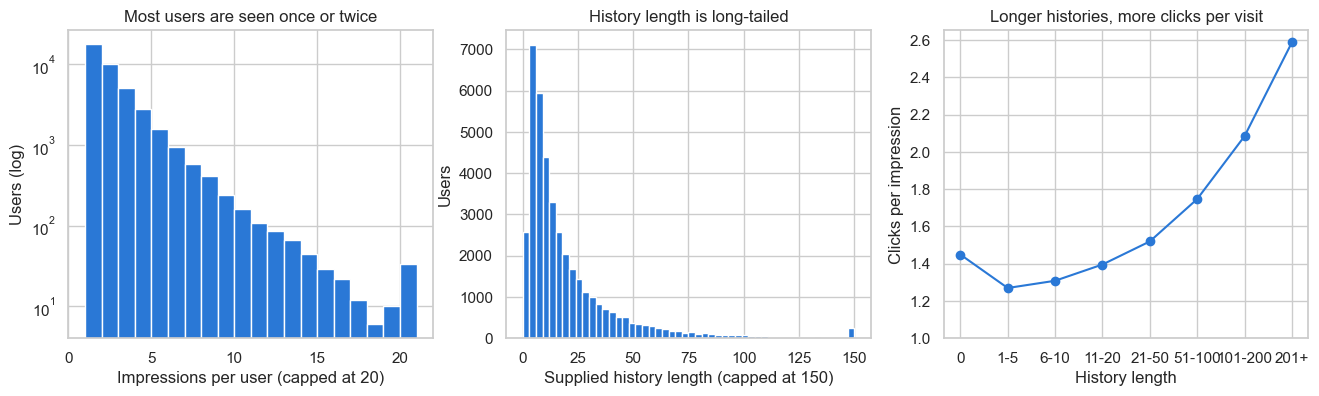

In [4]:
# Plot
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(users.impressions.clip(upper=20), bins=range(1, 22), log=True)
ax[0].set(xlabel="Impressions per user (capped at 20)", ylabel="Users (log)")
ax[0].set_title("Most users are seen once or twice")
ax[1].hist(users.history_len.clip(upper=150), bins=50)
ax[1].set(xlabel="Supplied history length (capped at 150)", ylabel="Users")
ax[1].set_title("History length is long-tailed")
ax[2].plot(by_hist.index.astype(str), by_hist.clicks_per_impression, marker="o")
ax[2].set(ylim=(1, None), xlabel="History length", ylabel="Clicks per impression")
ax[2].set_title("Longer histories, more clicks per visit")
plt.savefig(FIG_DIR / "usr_01_activity_history.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Cold-start users

Two kinds of cold start exist: users with **no supplied history** (1.8% of impressions) and users who appear in validation or test but
**never in train**.
* Users without history click about as much per visit as the others (1.45 vs 1.49).
* **28% of validation users and 29% of test users are new** relative to train (MIND-small samples 50,000 users, so a one-day split
  leaves many users unseen). They still carry a history, though a shorter one (median 9 against 25 for returning users), and click
  somewhat less per visit (1.4 against 1.6).

**Model Implications**
* Build user profiles from the supplied history plus content, which exist for new users; a user-id embedding would be undefined for almost
  a third of test users. Users with no history need an explicit fallback (popularity, freshness, category priors).

In [5]:
# 1. Users without a supplied history
no_hist = imp.groupby(imp.history_len == 0).agg(
    impressions=("n_clicks", "size"),
    clicks_per_impression=("n_clicks", "mean"),
)
no_hist.index.name = "no_history"
print(no_hist.round(3))

# 2. New users in validation and test relative to train
train_users = set(imp["user_code"])
rows = []
for split in ["validation", "test"]:
    d = pd.read_parquet(
        PROCESSED / f"impressions_{split}.parquet",
        columns=["user_code", "history_len", "n_clicks"],
    )
    d["new_user"] = ~d["user_code"].isin(train_users)
    g = (
        d.groupby("new_user")
        .agg(
            users=("user_code", "nunique"),
            impressions=("n_clicks", "size"),
            median_history=("history_len", "median"),
            clicks_per_impression=("n_clicks", "mean"),
        )
        .reset_index()
    )
    g["split"] = split
    g["user_share"] = 100 * g.users / g.users.sum()
    rows.append(g)
new_users = pd.concat(rows)
print("\nUsers in validation / test by whether they appear in train:")
print(new_users.round(2).to_string(index=False))

            impressions  clicks_per_impression
no_history                                    
False             93336                  1.490
True               1735                  1.449

Users in validation / test by whether they appear in train:
 new_user  users  impressions  median_history  clicks_per_impression      split  user_share
    False  15020        24074            25.0                   1.55 validation       71.92
     True   5864         7550             9.0                   1.41 validation       28.08
    False  14310        22648            26.0                   1.58       test       70.92
     True   5869         7622             9.0                   1.46       test       29.08


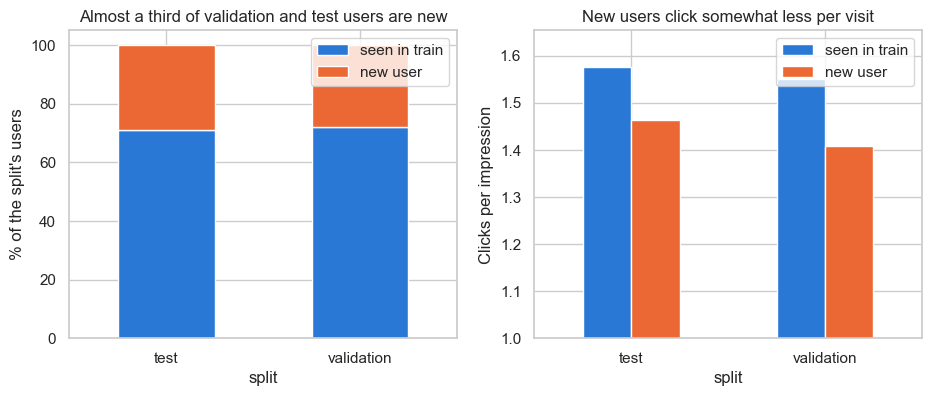

In [6]:
# Plot
share = new_users.pivot(index="split", columns="new_user", values="user_share")
cpi = new_users.pivot(index="split", columns="new_user", values="clicks_per_impression")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
share.plot(kind="bar", stacked=True, ax=ax[0], rot=0)
ax[0].legend(["seen in train", "new user"])
ax[0].set(
    ylabel="% of the split's users",
    title="Almost a third of validation and test users are new",
)
cpi.plot(kind="bar", ax=ax[1], rot=0)
ax[1].legend(["seen in train", "new user"])
ax[1].set(
    ylim=(1, None),
    ylabel="Clicks per impression",
    title="New users click somewhat less per visit",
)
plt.savefig(FIG_DIR / "usr_02_cold_start_users.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. The supplied history is a frozen snapshot: in-window clicks can extend it

A user's `history` string is identical across all of their impressions and across splits, so a returning user's test-day history does
**not** contain the clicks they made on 9 to 13 November, although those clicks are observed with labels.
* **80% of test users** (72% of validation users) have such clicks: a median of 4 per user, 19% more history in total.
* Inside the training window the same holds time-causally: 58% of impressions are preceded by an earlier click of the same user.

**Model Implications**
* Build the profile as **supplied history + in-window clicks strictly before the impression timestamp** (for the test day: all train and
  validation clicks of the user). This is leakage-free and shows the model the freshest interests.

In [7]:
# 1. Clicks observed inside the training and validation windows, per user
train_clicks = (
    cand[cand.clicked == 1].groupby("user_code").size().rename("train_clicks")
)
val_cand = pd.read_parquet(
    PROCESSED / "candidates_validation.parquet", columns=["user_code", "clicked"]
)
val_clicks = (
    val_cand[val_cand.clicked == 1].groupby("user_code").size().rename("val_clicks")
)
n_multi = int((imp.groupby("user_code").size() > 1).sum())
print("Users with > 1 impression:", n_multi)
print(
    "Users whose history changes between impressions: 0 (verified in data preparation)"
)

# 2. How much history could be added for validation and test users
for split in ["validation", "test"]:
    u = pd.read_parquet(
        PROCESSED / f"impressions_{split}.parquet", columns=["user_code", "history_len"]
    )
    u = u.drop_duplicates("user_code").set_index("user_code")
    u["added"] = train_clicks.reindex(u.index).fillna(0)
    if split == "test":
        u["added"] += val_clicks.reindex(u.index).fillna(0)
    has = u[u.added > 0]
    print(
        f"\n{split}: {100 * len(has) / len(u):.1f}% of users have in-window clicks not in their history"
    )
    print(
        f"  median {has.added.median():.0f} added clicks per such user (mean {has.added.mean():.1f})"
    )
    print(
        f"  +{100 * u.added.sum() / u.history_len.sum():.0f}% on top of the supplied history"
    )

# 3. Within train: impressions preceded by an earlier click of the same user
by_time = imp.sort_values(["user_code", "timestamp"])
clicks_before = by_time.groupby("user_code")["n_clicks"].cumsum() - by_time["n_clicks"]
print(
    f"\nTraining impressions preceded by an in-window click of the same user: {100 * (clicks_before > 0).mean():.1f}%"
)

Users with > 1 impression: 22341
Users whose history changes between impressions: 0 (verified in data preparation)

validation: 71.9% of users have in-window clicks not in their history
  median 3 added clicks per such user (mean 4.8)
  +14% on top of the supplied history

test: 80.2% of users have in-window clicks not in their history
  median 4 added clicks per such user (mean 5.9)
  +19% on top of the supplied history

Training impressions preceded by an in-window click of the same user: 57.8%


# 4. What histories contain

* The 806,306 history entries (once per user) cover **31,911 distinct articles**, of which only 2,077 were ever candidates in the window:
  histories are older than the slates. A typical user's history spans 6 categories.
* Histories lean more to news and sports than the slates MSN served in the window.

**Model Implications**
* Content-based user profiles are feasible (every history article has a title and category) and necessary: an id-based item model would see
  almost none of the history articles as candidates. Multi-category histories argue for multi-interest representations.

In [8]:
# 1. History entries once per user, joined to the article category
user_hist = pd.read_parquet(
    PROCESSED / "impressions_train.parquet", columns=["user_code", "history"]
)
user_hist = user_hist.drop_duplicates("user_code")
hist = explode_history(user_hist, "user_code")
hist = hist.merge(news, on="news_code", how="left")
shown_in_window = hist.loc[hist.exposures_train > 0, "news_code"].nunique()
print("History entries (once per user):", len(hist))
print(
    "Distinct articles in histories:",
    hist.news_code.nunique(),
    "| of which shown in the window:",
    shown_in_window,
)
print(
    "Median categories per user history:",
    hist.groupby("user_code").category.nunique().median(),
)

# 2. Category mix of histories against window exposures and clicks
exp = cand.merge(news[["news_code", "category"]], on="news_code")
exp = exp.groupby("category").agg(
    exposures=("clicked", "size"), clicks=("clicked", "sum")
)
mix = pd.DataFrame({"history": 100 * hist.category.value_counts(normalize=True)})
mix["exposures"] = 100 * exp.exposures / exp.exposures.sum()
mix["clicks"] = 100 * exp.clicks / exp.clicks.sum()
mix = mix.sort_values("history", ascending=False).head(12)
print("\nCategory share (%) of history entries vs window exposures and clicks:")
print(mix.round(1))

History entries (once per user): 806306
Distinct articles in histories: 31911 | of which shown in the window: 2077
Median categories per user history: 6.0

Category share (%) of history entries vs window exposures and clicks:
               history  exposures  clicks
category                                 
news              30.5       29.3    31.0
sports            14.2       11.1    14.0
lifestyle         10.6        9.5     8.4
tv                 7.6        4.6     7.3
finance            7.4        9.6     9.4
foodanddrink       5.2        5.8     4.0
health             4.8        5.2     4.1
movies             3.7        2.6     1.9
autos              3.6        4.3     2.8
entertainment      3.4        6.2     4.6
travel             3.2        4.8     3.2
music              2.6        4.3     6.8


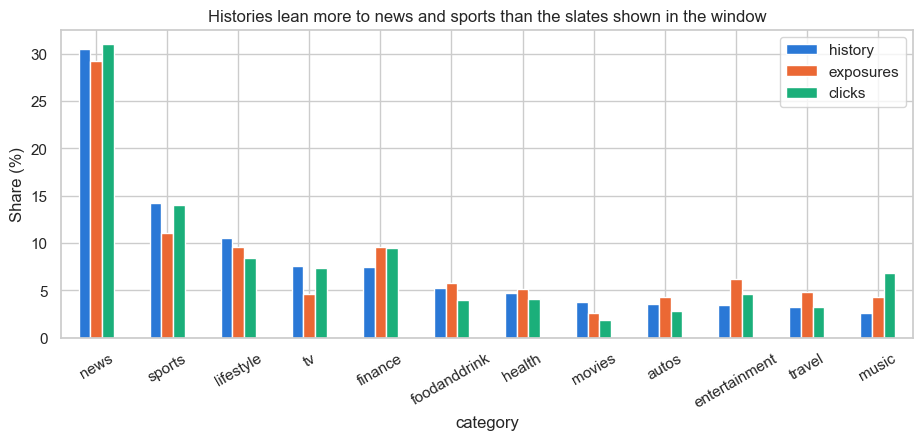

In [9]:
# Plot
mix.plot(kind="bar", figsize=(11, 4), rot=30)
plt.title("Histories lean more to news and sports than the slates shown in the window")
plt.ylabel("Share (%)")
plt.savefig(FIG_DIR / "usr_04_history_category_mix.png", dpi=150, bbox_inches="tight")
plt.show()
del hist

# 5. Does history-category affinity predict clicks?

For each impression we rebuild the user's category profile from the history: **affinity** = share of the user's past clicks in the candidate's
category. It uses only clicks before the window, so there is no target leakage.
* CTR rises monotonically from **3.0% at affinity 0 to 6.1% above 50%**, a 2× lift, and the gradient holds inside each of the four largest
  categories and on slates of length 50 to 100 (1.8% to 4.2%), so it is neither a category-mix nor a slate-size artefact.

**Model Implications**
* `category_affinity` is a strong, cheap, time-causal ranking feature. The lift is predictive, not causal: the existing recommender may already
  favour high-affinity items.

In [10]:
# 1. Category profile of each impression's history: share of past clicks per category
imp_hist = pd.read_parquet(
    PROCESSED / "impressions_train.parquet", columns=["impression_uid", "history"]
)
affinity = explode_history(imp_hist, "impression_uid").merge(
    news[["news_code", "category"]], on="news_code"
)
affinity = (
    affinity.groupby(["impression_uid", "category"]).size().rename("n").reset_index()
)
affinity["affinity"] = affinity.n / affinity.groupby("impression_uid").n.transform(
    "sum"
)
has_history = set(affinity.impression_uid)

# 2. Attach the affinity of each candidate's category (0 when the category is absent from the history)
cand_aff = cand.merge(news[["news_code", "category"]], on="news_code")
cand_aff = cand_aff.merge(imp[["impression_uid", "slate_len"]], on="impression_uid")
cand_aff = cand_aff.merge(
    affinity[["impression_uid", "category", "affinity"]],
    on=["impression_uid", "category"],
    how="left",
)
cand_aff["affinity"] = cand_aff.affinity.fillna(0.0)
cand_aff["has_history"] = cand_aff.impression_uid.isin(has_history)
labels = ["0", "0-5%", "5-10%", "10-20%", "20-30%", "30-50%", ">50%"]
cand_aff["affinity_bin"] = pd.cut(
    cand_aff.affinity, [-1, 0, 0.05, 0.1, 0.2, 0.3, 0.5, 1], labels=labels
)


# 3. Helper: exposures, clicks and CTR by one or more keys
def ctr_table(frame, keys):
    t = frame.groupby(keys, observed=True).agg(
        exposures=("clicked", "size"), clicks=("clicked", "sum")
    )
    t["ctr"] = 100 * t.clicks / t.exposures
    return t


# 4. CTR by affinity: all slates, size-controlled slates, and inside the four largest categories
mid_slates = cand_aff[cand_aff.slate_len.between(50, 100)]
top4 = ["news", "lifestyle", "sports", "finance"]
all_slates = ctr_table(cand_aff, "affinity_bin")
size_ctrl = ctr_table(mid_slates, "affinity_bin")
by_cat = ctr_table(
    cand_aff[cand_aff.category.isin(top4)], ["category", "affinity_bin"]
).reset_index()
print("CTR (%) by affinity bin, all slates:")
print(all_slates[["exposures", "ctr"]].round(2))
print("\nCTR (%) by affinity bin, slates of length 50-100:")
print(size_ctrl[["exposures", "ctr"]].round(2))
print("\nCTR (%) by affinity bin within the four largest categories:")
print(by_cat.pivot(index="affinity_bin", columns="category", values="ctr").round(2))

CTR (%) by affinity bin, all slates:
              exposures   ctr
affinity_bin                 
0                994393  3.03
0-5%             359893  3.10
5-10%            434998  3.71
10-20%           576679  4.50
20-30%           344158  5.14
30-50%           443783  5.88
>50%             235438  6.13

CTR (%) by affinity bin, slates of length 50-100:
              exposures   ctr
affinity_bin                 
0                324301  1.80
0-5%             127264  2.21
5-10%            151433  2.61
10-20%           198672  3.12
20-30%           117473  3.59
30-50%           145082  4.01
>50%              78383  4.22

CTR (%) by affinity bin within the four largest categories:
category      finance  lifestyle  news  sports
affinity_bin                                  
0                3.33       2.54  3.00    2.75
0-5%             3.48       1.94  1.64    2.26
5-10%            4.18       2.90  2.23    3.99
10-20%           4.83       4.14  3.34    5.78
20-30%           5.63       5

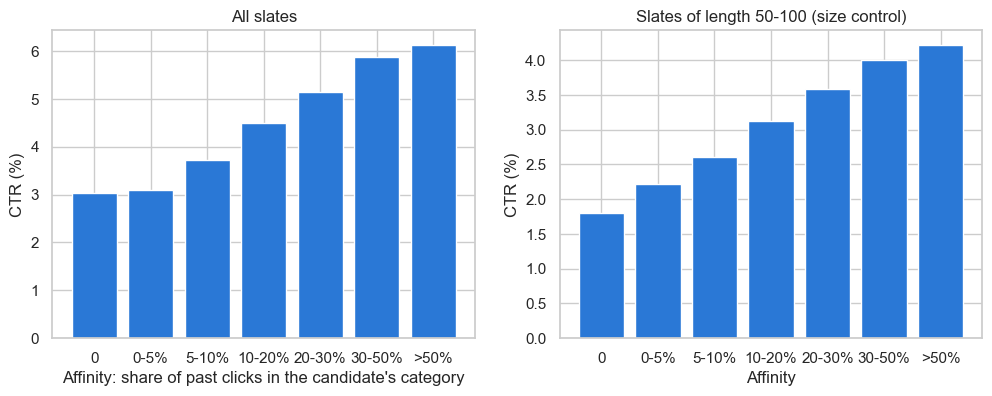

In [11]:
# Plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(labels, all_slates.ctr)
ax[0].set(
    xlabel="Affinity: share of past clicks in the candidate's category",
    ylabel="CTR (%)",
    title="All slates",
)
ax[1].bar(labels, size_ctrl.ctr)
ax[1].set(
    xlabel="Affinity", ylabel="CTR (%)", title="Slates of length 50-100 (size control)"
)
plt.savefig(FIG_DIR / "usr_05_affinity.png", dpi=150, bbox_inches="tight")
plt.show()

# 6. Novelty: does the category have to be in the history at all?

The affinity-0 bin mixes two situations: users with **no history** (cold users) and users whose history never touched the candidate's
category (**unseen category**).
* Seen-category candidates are clicked at **4.7%**, unseen-category candidates at **3.0%** (−36%), cold users at 4.1%; the ordering survives the
  size control. Unseen-category candidates are 0.93 M of 3.39 M exposures.

**Model Implications**
* History carries two distinct signals, intensity (affinity) and coverage (`seen_category`); keep both. Cold users behave like average users,
  so their fallback should be the population prior, not a pessimistic one.

In [12]:
# 1. Three groups of candidates
conditions = [~cand_aff.has_history, cand_aff.affinity == 0]
cand_aff["group"] = np.select(
    conditions, ["cold user", "unseen category"], default="seen category"
)
order = ["cold user", "unseen category", "seen category"]
nov = ctr_table(cand_aff, "group").reindex(order)
nov_ctrl = ctr_table(cand_aff[cand_aff.slate_len.between(50, 100)], "group").reindex(
    order
)
print("All slates:")
print(nov.round(2))
print("\nSlates of length 50-100:")
print(nov_ctrl.round(2))

All slates:
                 exposures  clicks   ctr
group                                   
cold user            61834    2514  4.07
unseen category     932559   27620  2.96
seen category      2394949  111424  4.65

Slates of length 50-100:
                 exposures  clicks   ctr
group                                   
cold user            19673     541  2.75
unseen category     304628    5287  1.74
seen category       818307   26321  3.22


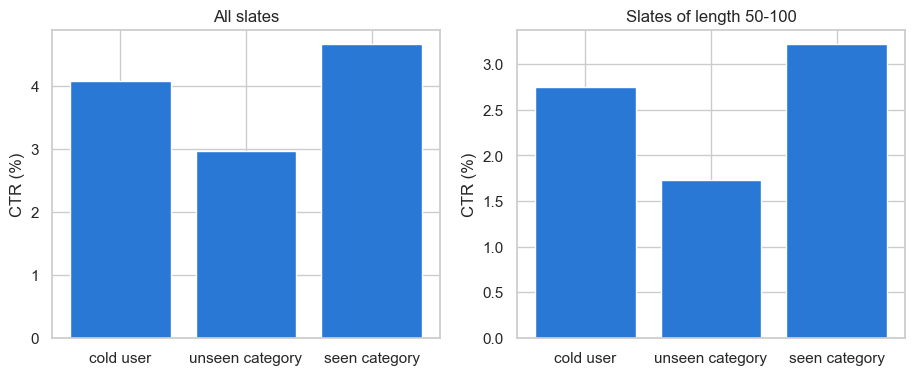

In [13]:
# Plot
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(order, nov.ctr)
ax[0].set(ylabel="CTR (%)", title="All slates")
ax[1].bar(order, nov_ctrl.ctr)
ax[1].set(ylabel="CTR (%)", title="Slates of length 50-100")
plt.savefig(FIG_DIR / "usr_06_novelty.png", dpi=150, bbox_inches="tight")
plt.show()
del cand_aff

# 7. Time since the previous visit: short-term carry-over vs long-term preference

For users with at least three impressions, each impression with a gap is compared with the categories clicked in the user's **previous
impression** (short-term context) and with the user's **most-clicked category** over the window (long-term).
* 27 to 29% of a visit's clicks repeat a category from the previous visit, almost regardless of the gap; the share of clicks in the user's
  top category sits between 42% and 47%. Within users the movements are about ±1 point except in the tiny 3-day-plus bucket (485
  visits), so most of the raw gradient is composition rather than a change of regime.

**Model Implications**
* Keep a recent component (last visit's clicks) next to the long-term profile; the gap itself is a weak switch between them.

In [14]:
# 1. Visits with a gap, for users with at least three impressions
GAPS = ["<1 hour", "1-6 hours", "6-24 hours", "1-3 days", ">3 days"]
sess = imp[["impression_uid", "user_code", "timestamp"]].sort_values(
    ["user_code", "timestamp"]
)
by_user = sess.groupby("user_code")
sess["gap_h"] = by_user.timestamp.diff().dt.total_seconds() / 3600
sess["prev_uid"] = by_user.impression_uid.shift(1)
sess["n_visits"] = by_user.impression_uid.transform("size")
sess = sess[(sess.n_visits >= 3) & sess.gap_h.notna()].copy()
sess["gap"] = pd.cut(sess.gap_h, [-1, 1, 6, 24, 72, 1e9], labels=GAPS)

# 2. Clicked categories, one row per click
clicks = cand[cand.clicked == 1][["impression_uid", "user_code", "news_code"]]
clicks = clicks.merge(news[["news_code", "category"]], on="news_code")

# 3. Two references: categories clicked in the previous visit, and each user's most-clicked category
prev_cats = clicks[["impression_uid", "category"]].drop_duplicates()
prev_cats = prev_cats.rename(columns={"impression_uid": "prev_uid"})
prev_cats["in_prev"] = 1.0

top_cat = clicks.groupby(["user_code", "category"]).size().reset_index(name="n")
top_cat = top_cat.sort_values("n", ascending=False).drop_duplicates("user_code")
top_cat = top_cat[["user_code", "category"]]
top_cat["in_top"] = 1.0

# 4. For every click in a visit with a gap: is its category in the previous visit? is it the user's top category?
visit = clicks.merge(sess[["impression_uid", "gap", "prev_uid"]], on="impression_uid")
visit = visit.merge(prev_cats, on=["prev_uid", "category"], how="left")
visit = visit.merge(top_cat, on=["user_code", "category"], how="left")
visit[["in_prev", "in_top"]] = visit[["in_prev", "in_top"]].fillna(0.0)
visit = visit.groupby(["impression_uid", "user_code", "gap"], observed=True)[
    ["in_prev", "in_top"]
].mean()
visit = visit.reset_index()

# 5. Raw bucket means and within-user demeaned means
raw = visit.groupby("gap", observed=True)[["in_prev", "in_top"]].mean().reindex(GAPS)
dem = visit.copy()
dem[["in_prev", "in_top"]] -= dem.groupby("user_code")[["in_prev", "in_top"]].transform(
    "mean"
)
dem = dem.groupby("gap", observed=True)[["in_prev", "in_top"]].mean().reindex(GAPS)
print(
    f"Users with >= 3 impressions: {visit.user_code.nunique():,} | visits with a gap: {len(visit):,}"
)
print(
    "\nShare of the visit's clicks (%) in a category of the previous visit / in the user's top category:"
)
print((100 * raw).round(1))
print("\nWithin-user demeaned (percentage points):")
print((100 * dem).round(2))

Users with >= 3 impressions: 12,306 | visits with a gap: 44,888

Share of the visit's clicks (%) in a category of the previous visit / in the user's top category:
            in_prev  in_top
gap                        
<1 hour        27.0    43.2
1-6 hours      27.5    42.0
6-24 hours     28.9    46.4
1-3 days       28.7    47.4
>3 days        23.3    46.4

Within-user demeaned (percentage points):
            in_prev  in_top
gap                        
<1 hour       -0.19   -0.08
1-6 hours     -0.20   -1.10
6-24 hours     0.38    1.17
1-3 days      -0.11   -0.19
>3 days       -3.65   -4.52


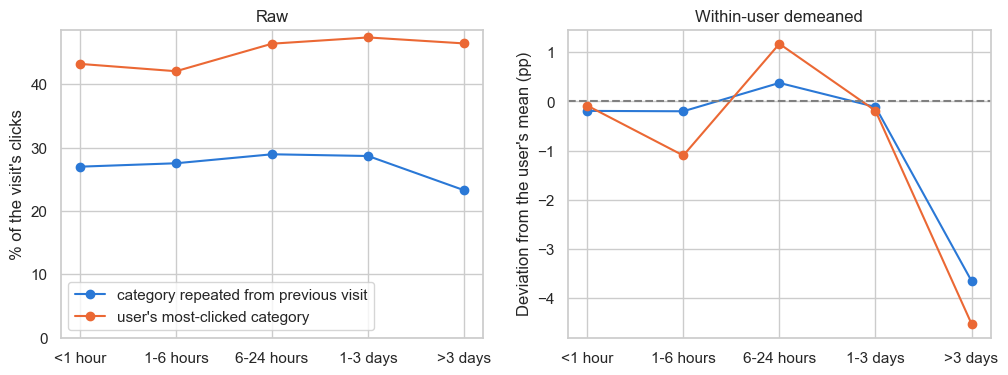

In [15]:
# Plot
series = [
    ("in_prev", "category repeated from previous visit"),
    ("in_top", "user's most-clicked category"),
]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for col, lab in series:
    ax[0].plot(GAPS, 100 * raw[col], marker="o", label=lab)
    ax[1].plot(GAPS, 100 * dem[col], marker="o", label=lab)
ax[0].set(ylim=(0, None), ylabel="% of the visit's clicks", title="Raw")
ax[0].legend()
ax[1].axhline(0, color="grey", ls="--")
ax[1].set(ylabel="Deviation from the user's mean (pp)", title="Within-user demeaned")
plt.savefig(FIG_DIR / "usr_07_short_vs_long_term.png", dpi=150, bbox_inches="tight")
plt.show()

# Summary

| Finding | Decision |
|---|---|
| Median user has 2 impressions; history median 12 per user, p95 66 | history cap ≈ 50; rely on history + content |
| 1.8% of impressions have no history; 28–29% of validation / test users are new | content-based profiles; explicit no-history fallback; report new vs returning users |
| Histories are frozen snapshots; 80% of test users have labelled in-window clicks | profile = supplied history + in-window clicks before the impression time |
| History articles mostly never appear as candidates; ~6 categories per user | content is the bridge; multi-interest representation |
| Affinity lifts CTR 2×, robust to category and slate size | `category_affinity` feature |
| Unseen category −36% CTR; cold users ≈ average | `seen_category` flag; population prior for cold users |
| Gap effects are within ±1 pp inside users | recent + long-term components; gap is a weak switch |